# 01 · Análisis exploratorio (EDA) — Dry Bean Dataset
**Sprint 1 · CRISP-DM fase 2: Comprensión de los datos** · Backlog: PB-01 (cargar datos) y PB-02 (calidad de datos)

Preguntas que responde este notebook:
1. ¿Qué contiene el dataset y de qué tipo son las variables?
2. ¿Hay nulos o duplicados?
3. ¿Las clases están balanceadas?
4. ¿Cómo se distribuyen las variables y hay valores atípicos?
5. ¿Qué variables están correlacionadas entre sí?
6. ¿Qué tan separables son las clases?

**Este notebook no modifica los datos:** solo los describe y diagnostica. La limpieza, se hace en la fase de **Preparación**, en el notebook 02.

## 1. Carga de datos desde UCI

In [14]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset
dry_bean = fetch_ucirepo(id=602)

# data (as pandas dataframes)
X = dry_bean.data.features
y = dry_bean.data.targets

# metadata
print(dry_bean.metadata)

# variable information
print(dry_bean.variables)

{'uci_id': 602, 'name': 'Dry Bean', 'repository_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/602/data.csv', 'abstract': 'Images of 13,611 grains of 7 different registered dry beans were taken with a high-resolution camera. A total of 16 features; 12 dimensions and 4 shape forms, were obtained from the grains.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 13611, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Thu Mar 28 2024', 'dataset_doi': '10.24432/C50S4B', 'creators': [], 'intro_paper': {'ID': 244, 'type': 'NATIVE', 'title': 'Multiclass classification of dry beans using computer vision and machine learning techniques', 'authors': 'M. Koklu, Ilker Ali Özkan', 'venue': 'Co

## 2. Librerías y dataframe completo

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

df = pd.concat([X, y], axis=1)
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.2910,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.0180,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.1100,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.8840,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.1340,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

**Lectura:** 13.611 registros y 17 columnas. Las 16 predictoras son numéricas (14 `float64` y 2 `int64`: `Area` y `ConvexArea`); `Class` es texto. Es un problema de **clasificación multiclase**.

Las variables son de dos tipos:
- **Dimensiones** (en píxeles): `Area`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength`, `ConvexArea`, `EquivDiameter`.
- **Forma** (adimensionales): `AspectRation`, `Eccentricity`, `Extent`, `Solidity`, `roundness`, `Compactness`, `ShapeFactor1` a `ShapeFactor4`.

Nota: `AspectRation` viene así en el archivo original (debería ser *AspectRatio*).

## 3. Calidad de datos: nulos y duplicados

In [17]:
missing_values = df.isna().sum()
duplicated_rows = df.duplicated().sum()

print("Nulos totales:", missing_values.sum())
print("Filas duplicadas:", duplicated_rows)

Nulos totales: 0
Filas duplicadas: 68


In [18]:
# ¿De qué clase son los duplicados? (keep=False marca todas las copias)
df[df.duplicated(keep=False)]["Class"].value_counts()

,count
Class,
HOROZ,136


**Lectura:** no hay valores nulos. Hay **68 filas duplicadas, todas de la clase HOROZ**: son idénticas en las 17 columnas, con decimales hasta la millonésima, así que se interpretan como el mismo grano registrado dos veces.

**Recomendación para la preparación (notebook 02):** eliminarlas. Si se dejan, una misma fila puede quedar en entrenamiento y en prueba a la vez, y eso infla las métricas. En este notebook se conservan, porque el EDA describe los datos tal como llegan.

## 4. Variable objetivo: distribución de clases

In [19]:
class_counts = df["Class"].value_counts()
resumen_clases = pd.DataFrame({
    "registros": class_counts,
    "porcentaje": (class_counts / len(df) * 100).round(1),
})
print("Razón clase mayor / clase menor:", round(class_counts.max() / class_counts.min(), 1))
resumen_clases

Razón clase mayor / clase menor: 6.8


,registros,porcentaje
Class,,
DERMASON,3546,26.1000
SIRA,2636,19.4000
SEKER,2027,14.9000
HOROZ,1928,14.2000
CALI,1630,12.0000
BARBUNYA,1322,9.7000
BOMBAY,522,3.8000


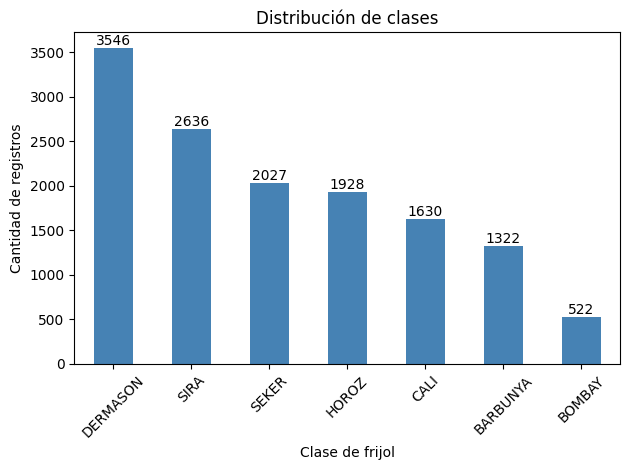

In [20]:
ax = class_counts.plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Distribución de clases")
plt.xlabel("Clase de frijol")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Lectura:** las clases **no están balanceadas**. DERMASON tiene 3.546 registros (26,1 %) y BOMBAY solo 522 (3,8 %): unas 6,8 veces menos.

**Consecuencia para el modelado:** el modelo tenderá a favorecer las clases grandes, y el accuracy puede verse bien aunque falle en BOMBAY. Por eso conviene:
- separar train/test con `stratify=y`;
- probar `class_weight="balanced"`;
- evaluar con **F1 macro**, que pesa igual a todas las clases.

## 5. Estadística descriptiva y escalas

In [21]:
desc = df.describe().T
desc["coef_variacion"] = desc["std"] / desc["mean"]
desc["asimetria"] = df.drop(columns="Class").skew()
desc[["mean", "std", "min", "50%", "max", "coef_variacion", "asimetria"]].sort_values("mean", ascending=False)

,mean,std,min,50%,max,coef_variacion,asimetria
ConvexArea,"53,768.2002","29,774.9158","20,684.0000","45,178.0000","263,261.0000",0.5538,2.9418
Area,"53,048.2845","29,324.0957","20,420.0000","44,652.0000","254,616.0000",0.5528,2.9529
Perimeter,855.2835,214.2897,524.7360,794.9410,"1,985.3700",0.2505,1.6261
MajorAxisLength,320.1419,85.6942,183.6012,296.8834,738.8602,0.2677,1.3578
EquivDiameter,253.0642,59.1771,161.2438,238.4380,569.3744,0.2338,1.9490
MinorAxisLength,202.2707,44.9701,122.5127,192.4317,460.1985,0.2223,2.2382
AspectRatio,1.5832,0.2467,1.0249,1.5511,2.4303,0.1558,0.5826
ShapeFactor4,0.9951,0.0044,0.9477,0.9964,0.9997,0.0044,-2.7595
Solidity,0.9871,0.0047,0.9192,0.9883,0.9947,0.0047,-2.5501
Roundness,0.8733,0.0595,0.4896,0.8832,0.9907,0.0682,-0.6357


**Lectura:**
- **Escalas muy distintas:** `Area` está alrededor de 53.000 píxeles, mientras `ShapeFactor2` está cerca de 0,002. Los modelos basados en distancias o gradiente (regresión logística, KNN, SVM) necesitan **estandarizar**. Los árboles no.
- **Variabilidad:** `Area` y `ConvexArea` son las que más varían (coeficiente de variación ≈ 0,55). `ShapeFactor4` y `Solidity` casi no varían (≈ 0,004): todos los granos son casi igual de "sólidos".
- **Asimetría:** las variables de tamaño tienen cola a la derecha (asimetría de 1,4 a 2,9) por los granos grandes. `ShapeFactor4` y `Solidity` tienen cola a la izquierda (≈ −2,5 a −2,8).

## 6. Distribución de cada variable

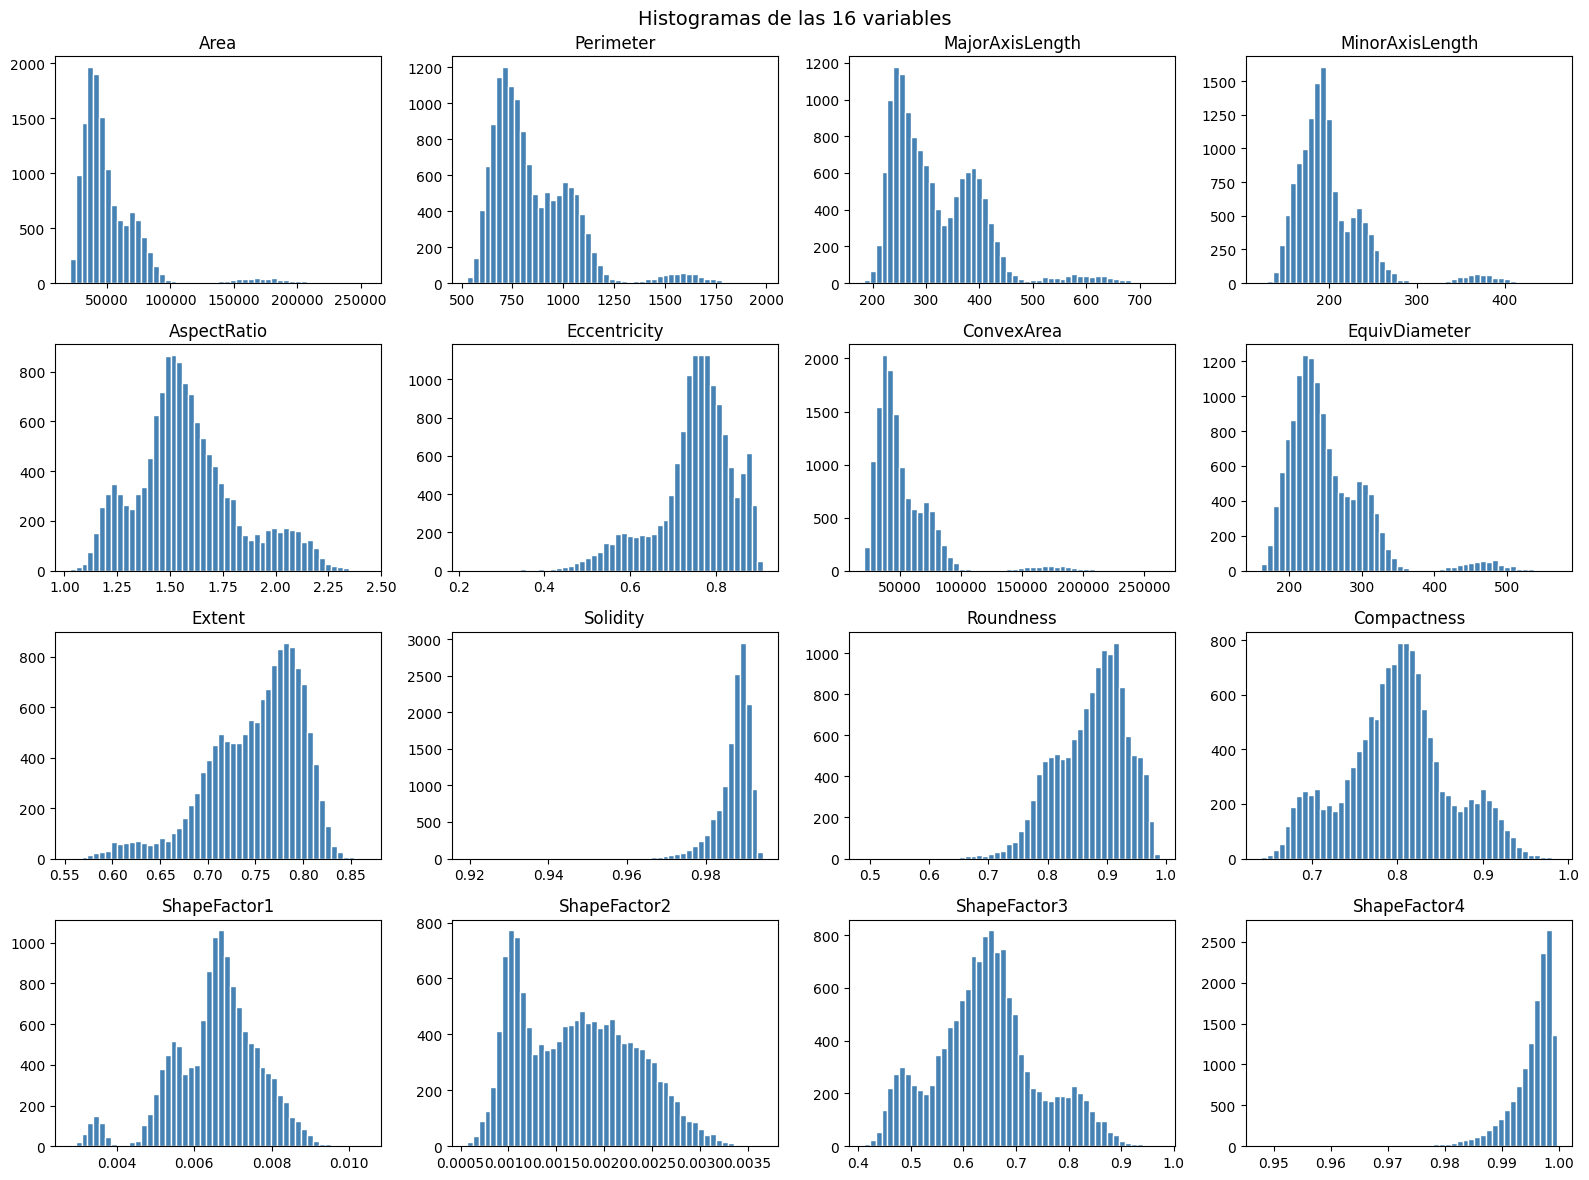

In [22]:
features = df.drop(columns="Class").columns

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col], bins=50, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.suptitle("Histogramas de las 16 variables", fontsize=14)
plt.tight_layout()
plt.show()

**Lectura:** las variables de tamaño (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`...) muestran un **grupo separado a la derecha**: son los granos BOMBAY, mucho más grandes. Varias variables de forma son **bimodales o multimodales**, una pista de que distintas variedades tienen formas distintas.

## 7. Valores atípicos (regla IQR)

In [23]:
X_num = df[features]
q1, q3 = X_num.quantile(0.25), X_num.quantile(0.75)
iqr = q3 - q1
es_atipico = (X_num < q1 - 1.5 * iqr) | (X_num > q3 + 1.5 * iqr)

print("Filas con al menos un valor atípico:", es_atipico.any(axis=1).sum())
es_atipico.sum().sort_values(ascending=False).to_frame("atipicos")

Filas con al menos un valor atípico: 3017


,atipicos
Eccentricity,843
Solidity,778
ShapeFactor4,767
MinorAxisLength,569
Area,551
ConvexArea,550
ShapeFactor1,533
EquivDiameter,526
Perimeter,500
AspectRatio,473


In [24]:
# ¿A qué clase pertenecen los atípicos de Area?
df.loc[es_atipico["Area"], "Class"].value_counts()

,count
Class,
BOMBAY,522
CALI,24
BARBUNYA,5


**Lectura:** según la regla IQR, unas 3.000 filas (22 %) tienen al menos un valor "atípico". Pero los atípicos de `Area` son **todos los 522 BOMBAY** más unos pocos CALI y BARBUNYA. **No son errores de medición: son granos reales de variedades grandes.**

**Decisión:** no se eliminan. Quitarlos borraría casi toda la clase BOMBAY. La regla IQR supone una sola población, y aquí hay 7 variedades mezcladas.

## 8. Variables por clase (boxplots)

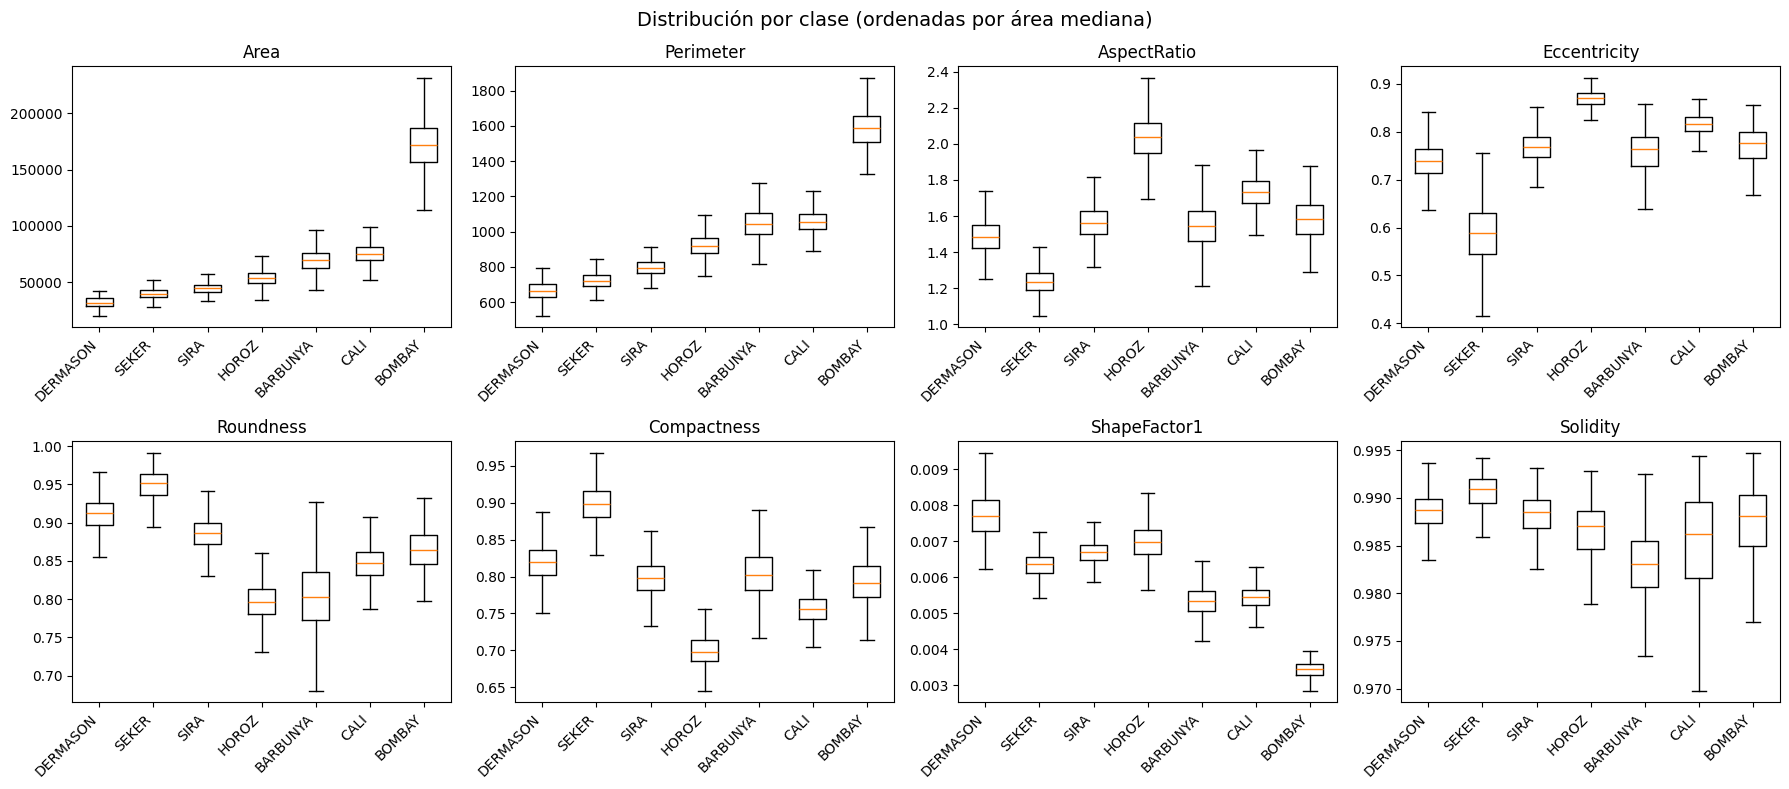

In [25]:
orden = df.groupby("Class")["Area"].median().sort_values().index
vars_clave = ["Area", "Perimeter", "AspectRatio", "Eccentricity", "Roundness", "Compactness", "ShapeFactor1", "Solidity"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), vars_clave):
    ax.boxplot([df.loc[df["Class"] == c, col] for c in orden], showfliers=False)
    ax.set_xticks(range(1, len(orden) + 1), orden, rotation=45, ha="right")
    ax.set_title(col)
plt.suptitle("Distribución por clase (ordenadas por área mediana)", fontsize=14)
plt.tight_layout()
plt.show()

In [26]:
df.groupby("Class")[vars_clave].median().loc[orden]

,Area,Perimeter,AspectRatio,Eccentricity,Roundness,Compactness,ShapeFactor1,Solidity
Class,,,,,,,,
DERMASON,"31,890.0000",664.5230,1.4847,0.7392,0.9123,0.8195,0.0077,0.9887
SEKER,"39,180.0000",721.2920,1.2362,0.5879,0.9517,0.8987,0.0064,0.9909
SIRA,"44,593.0000",794.9895,1.5624,0.7683,0.8865,0.7983,0.0067,0.9885
HOROZ,"53,800.5000",921.3955,2.0366,0.8711,0.7960,0.6980,0.0070,0.9870
BARBUNYA,"69,582.0000","1,045.0600",1.5478,0.7633,0.8032,0.8024,0.0053,0.9831
CALI,"74,791.5000","1,055.4725",1.7339,0.8169,0.8466,0.7555,0.0055,0.9862
BOMBAY,"171,494.5000","1,586.2375",1.5863,0.7763,0.8647,0.7911,0.0035,0.9881


**Lectura:**
- **BOMBAY** se separa sola por tamaño (mediana de área ≈ 171.500 px, más del doble que cualquier otra).
- **DERMASON y SIRA** son las más pequeñas y sus cajas se traslapan en casi todas las variables: probablemente serán **el par más difícil de distinguir**.
- **BARBUNYA y CALI** tienen tamaños parecidos; CALI es más alargada (`AspectRation` mayor).
- **HOROZ** es la más alargada y la menos redonda; **SEKER** la más redonda. La forma las separa aunque el tamaño se parezca.

## 9. Correlación entre variables

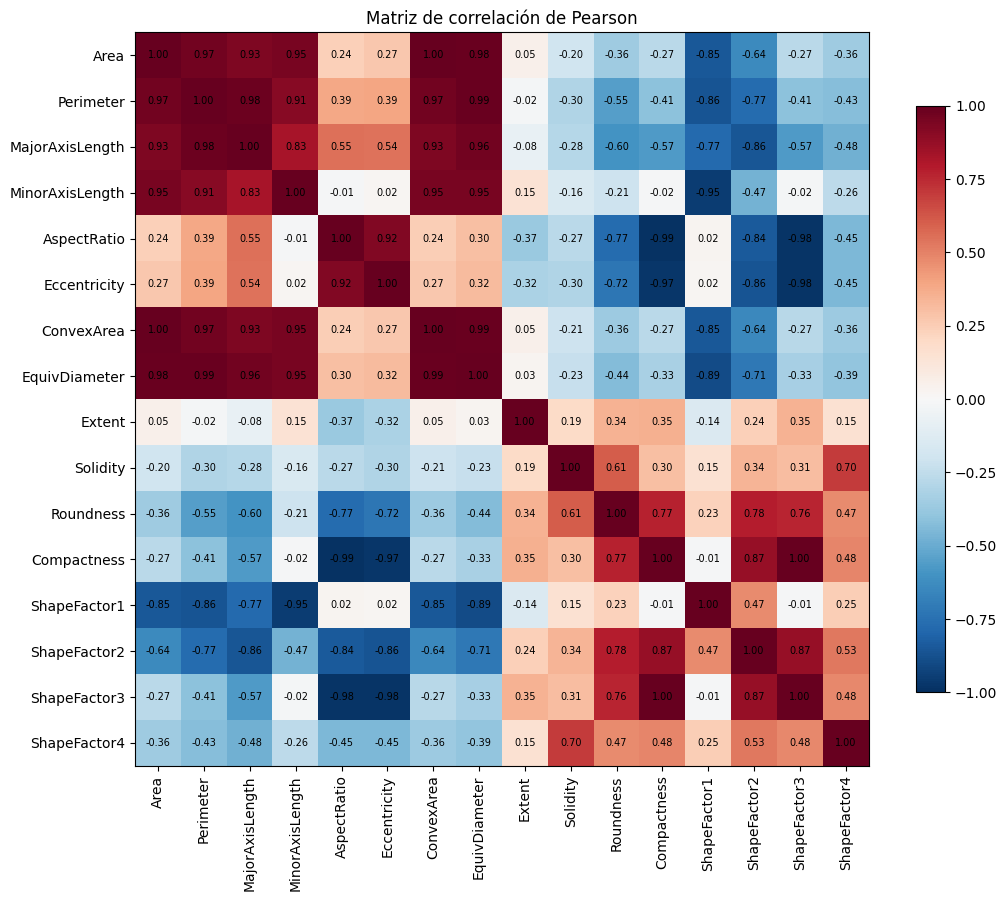

In [27]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=90)
ax.set_yticks(range(len(features)), features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

In [28]:
# Pares con |correlación| > 0.9
pares = (
    corr.abs()
    .where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .sort_values(ascending=False)
)
pares_altos = pares[pares > 0.9].to_frame("abs_corr")
print("Pares con |r| > 0.9:", len(pares_altos))
pares_altos

Pares con |r| > 0.9: 21


,,abs_corr
Area,ConvexArea,0.9999
Compactness,ShapeFactor3,0.9987
Perimeter,EquivDiameter,0.9914
AspectRatio,Compactness,0.9877
ConvexArea,EquivDiameter,0.9852
Area,EquivDiameter,0.9850
Eccentricity,ShapeFactor3,0.9811
AspectRatio,ShapeFactor3,0.9786
Perimeter,MajorAxisLength,0.9773
Eccentricity,Compactness,0.9703


**Lectura:** hay **21 pares con |r| > 0,9**. Varias variables miden casi lo mismo:
- `Area` y `ConvexArea` (r ≈ 1,00), `Perimeter` y `EquivDiameter` (0,99): todas son "tamaño".
- `Compactness` y `ShapeFactor3` (0,999), `AspectRation` y `Compactness` (0,99): todas son "alargamiento".

**Implicaciones:**
- Para la **regresión logística**, la multicolinealidad puede volver inestables los coeficientes, aunque no suele afectar mucho las predicciones.
- En **Random Forest**, la importancia de variables se "reparte" entre variables correlacionadas, así que hay que interpretarla con cuidado.
- Es una oportunidad para reducir variables (selección o PCA) si se quiere un modelo más simple.

## 10. ¿Qué tan separables son las clases?

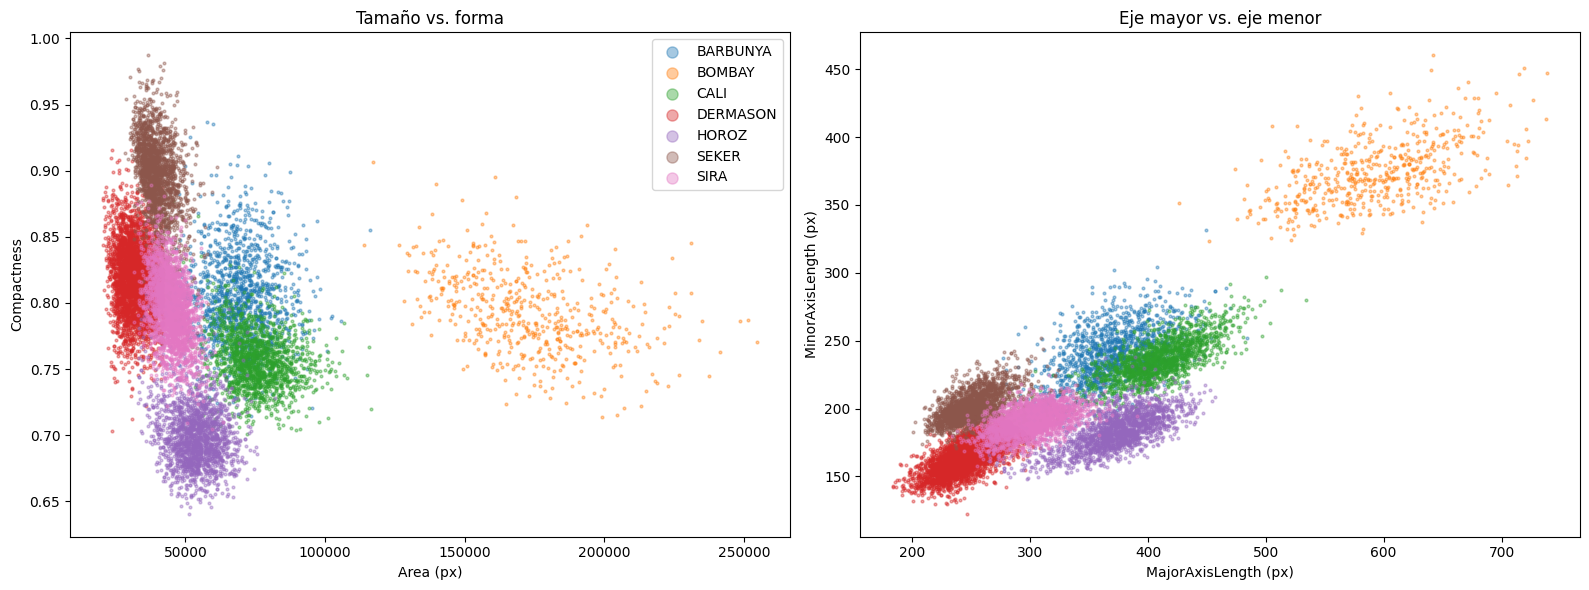

In [29]:
colores = dict(zip(sorted(df["Class"].unique()), plt.cm.tab10.colors))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for c, g in df.groupby("Class"):
    axes[0].scatter(g["Area"], g["Compactness"], s=4, alpha=0.4, color=colores[c], label=c)
    axes[1].scatter(g["MajorAxisLength"], g["MinorAxisLength"], s=4, alpha=0.4, color=colores[c], label=c)
axes[0].set(xlabel="Area (px)", ylabel="Compactness", title="Tamaño vs. forma")
axes[1].set(xlabel="MajorAxisLength (px)", ylabel="MinorAxisLength (px)", title="Eje mayor vs. eje menor")
axes[0].legend(markerscale=4)
plt.tight_layout()
plt.show()

Varianza explicada acumulada (primeros 5 componentes): [0.555 0.819 0.899 0.95  0.978]


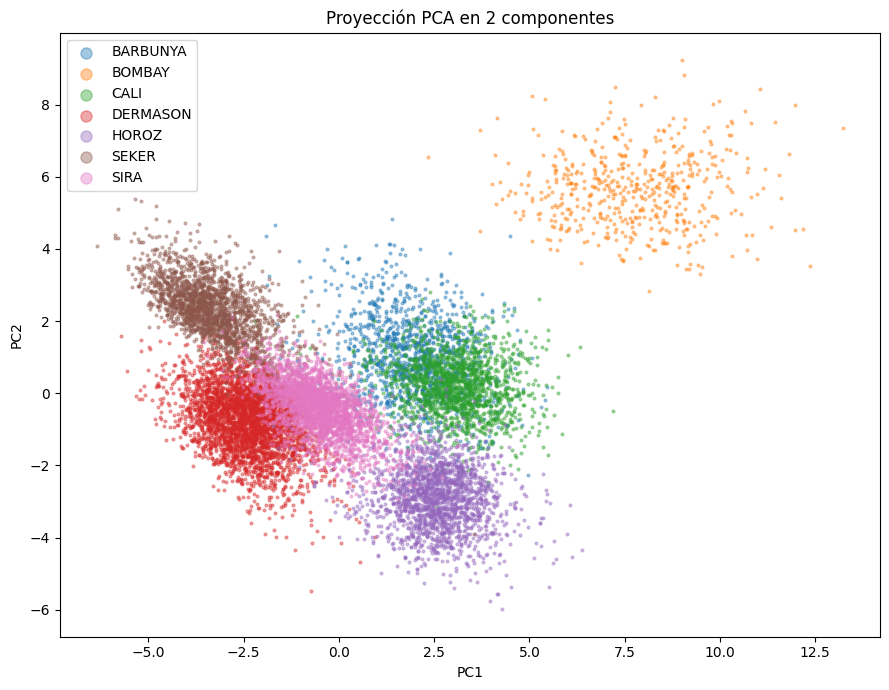

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_std = StandardScaler().fit_transform(df[features])
pca = PCA().fit(X_std)
print("Varianza explicada acumulada (primeros 5 componentes):",
      np.round(np.cumsum(pca.explained_variance_ratio_)[:5], 3))

Z = pca.transform(X_std)[:, :2]
plt.figure(figsize=(9, 7))
for c in sorted(df["Class"].unique()):
    m = (df["Class"] == c).to_numpy()
    plt.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.4, color=colores[c], label=c)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Proyección PCA en 2 componentes")
plt.legend(markerscale=4)
plt.tight_layout()
plt.show()

**Lectura:**
- Con solo **2 componentes principales se explica ~82 % de la varianza**, y con 4 ~95 %: confirma que muchas de las 16 variables son redundantes.
- En la proyección, **BOMBAY** forma una nube aislada, y **HOROZ** y **SEKER** quedan en zonas bien definidas.
- **DERMASON–SIRA** y **BARBUNYA–CALI** se solapan: ahí se esperan la mayoría de los errores del modelo.
- Aun así, las clases están bastante separadas: se espera que incluso un modelo lineal logre un desempeño alto (> 90 %).

## 11. Guardar una copia de los datos crudos en Drive
Se guarda el dataset **tal como llegó de UCI**, sin cambios, para que el notebook de preparación trabaje sobre una copia fija aunque UCI cambie o no responda. En TDSP este archivo corresponde a `data/raw/`.

In [31]:
from google.colab import drive
drive.mount("/content/drive")

df.to_csv("/content/drive/MyDrive/drybean_raw.csv", index=False)
print("Guardado:", df.shape)

Mounted at /content/drive
Guardado: (13611, 17)


## 12. Conclusiones del EDA → decisiones para la preparación

| Hallazgo | Decisión |
| --- | --- |
| 0 nulos | No se necesita imputación |
| 68 duplicados (todos HOROZ) | Eliminarlos en la preparación → quedarían 13.543 registros |
| Clases desbalanceadas (6,8:1) | `stratify=y`, `class_weight="balanced"`, métrica F1 macro |
| Escalas muy distintas | `StandardScaler` dentro de un `Pipeline` para modelos lineales |
| Atípicos = granos BOMBAY reales | No se eliminan |
| 21 pares con \|r\| > 0,9 | Tener cuidado al interpretar coeficientes e importancias; opción de PCA |
| DERMASON–SIRA y BARBUNYA–CALI se solapan | Revisar esos pares en la matriz de confusión |

**Siguiente paso (notebook 02, Preparación):** eliminar duplicados, LabelEncoder, SMOTE y StandardScaler.